In [ ]:
# This serves as a template which will guide you through the implementation of this task.  It is advised
# to first read the whole template and get a sense of the overall structure of the code before trying to fill in any of the TODO gaps
# First, we import necessary libraries:
import os
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import transforms
import torchvision.datasets as datasets
import torchvision.models as models

# Check if running on google colab or elsewhere
if 'google.colab' in str(get_ipython()):
    print('Running on CoLab')
    %cd /content/drive/MyDrive/task3
else:
    print('Not running on CoLab')

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

EMBEDDING_SIZE = 512

def generate_embeddings():
    """
    Transform, resize and normalize the images and then use a pretrained model to extract 
    the embeddings.
    """
    # TODO: define a transform to pre-process the images
    train_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    train_dataset = datasets.ImageFolder(root="dataset/", transform=train_transforms)
    # Hint: adjust batch_size and num_workers to your PC configuration, so that you don't 
    # run out of memory
    train_loader = DataLoader(dataset=train_dataset,
                              batch_size=64,
                              shuffle=False,
                              pin_memory=True, num_workers=2)

    # TODO: define a model for extraction of the embeddings (Hint: load a pretrained model,
    #  more info here: https://pytorch.org/vision/stable/models.html)
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    
    embeddings = []
    # Last layer of model
    embedding_size = EMBEDDING_SIZE # Dummy variable, replace with the actual embedding size once you 
    # pick your model
    num_images = len(train_dataset) # 10000
    embeddings = np.zeros((num_images, embedding_size)) # (10000, embedding_size)
    # TODO: Use the model to extract the embeddings. Hint: remove the last layers of the 
    # model to access the embeddings the model generates.

    # Remove the last layer of model
    model = torch.nn.Sequential(*list(model.children())[:-1])

    # Move model to gpu if gpu is available
    model.to(device)
    
    # Set model to evaluation mode
    model.eval()
    
    # temporarily sets all of the requires_grad flags to false
    with torch.no_grad():
        for i, data in enumerate(train_loader):
            inputs, _ = data # no labels
            # Move data to gpu if gpu is available
            inputs = inputs.to(device)
            outputs = model(inputs)
            # first move data from gpu (if used) to cpu memory. Data consists of BATCH_SIZE samples. 
            output_np = outputs.cpu().numpy() # shape: (64, EMBEDDING_SIZE, 1, 1)
            # last batch has size 16
            output_np = np.reshape(output_np, (16 if inputs.shape[0] == 16 else 64, embedding_size))
            embeddings[i*train_loader.batch_size: (i+1)*train_loader.batch_size] = output_np
    
    np.save('dataset/embeddings.npy', embeddings)


def get_data(file, train=True):
    """
    Load the triplets from the file and generate the features and labels.

    input: file: string, the path to the file containing the triplets
          train: boolean, whether the data is for training or testing

    output: X: numpy array, the features
            y: numpy array, the labels
    """
    triplets = []
    with open(file) as f:
        for line in f:
            triplets.append(line)

    # generate training data from triplets
    train_dataset = datasets.ImageFolder(root="dataset/",
                                         transform=None)
    # Rename file names from '00000.jpg' to '00000'
    filenames = [s[0].split('/')[-1].replace('.jpg', '') for s in train_dataset.samples]
    embeddings = np.load('dataset/embeddings.npy') # (10000, EMBEDDING_SIZE)
    # TODO: Normalize the embeddings across the dataset
    embeddings = (embeddings-embeddings.min())/(embeddings.max()-embeddings.min())
    
    file_to_embedding = {}
    for i in range(len(filenames)):
        file_to_embedding[filenames[i]] = embeddings[i]
    X = []
    y = []
    # use the individual embeddings to generate the features and labels for triplets
    for t in triplets:
        emb = [file_to_embedding[a] for a in t.split()]
        X.append(np.hstack([emb[0], emb[1], emb[2]]))
        y.append(1)
        # Generating negative samples (data augmentation)
        if train:
            X.append(np.hstack([emb[0], emb[2], emb[1]]))
            y.append(0)
    X = np.vstack(X)
    y = np.hstack(y)
    return X, y

# Hint: adjust batch_size and num_workers to your PC configuration, so that you don't run out of memory
def create_loader_from_np(X, y = None, train = True, batch_size=64, shuffle=True, num_workers = 4):
    """
    Create a torch.utils.data.DataLoader object from numpy arrays containing the data.

    input: X: numpy array, the features
           y: numpy array, the labels
    
    output: loader: torch.data.util.DataLoader, the object containing the data
    """
    if train:
        dataset = TensorDataset(torch.from_numpy(X).type(torch.float), 
                                torch.from_numpy(y).type(torch.long))
    else:
        dataset = TensorDataset(torch.from_numpy(X).type(torch.float))
    loader = DataLoader(dataset=dataset,
                        batch_size=batch_size,
                        shuffle=shuffle,
                        pin_memory=True, num_workers=num_workers)
    return loader

# TODO: define a model. Here, the basic structure is defined, but you need to fill in the details
class Net(nn.Module):
    """
    The model class, which defines our classifier.
    """
    def __init__(self):
        """
        The constructor of the model.
        """
        super().__init__()
        self.fc1 = nn.Linear(3*EMBEDDING_SIZE, 1024)
        self.fc2 = nn.Linear(1024, 256)
        self.fc3 = nn.Linear(256, 64)
        self.fc4 = nn.Linear(64, 1)

    def forward(self, x):
        """
        The forward pass of the model.

        input: x: torch.Tensor, the input to the model

        output: x: torch.Tensor, the output of the model
        """
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        x = self.fc3(x)
        x = F.relu(x)
        x = self.fc4(x)
        x = torch.sigmoid(x)
        return x

def train_model(train_loader):
    """
    The training procedure of the model; it accepts the training data, defines the model 
    and then trains it.

    input: train_loader: torch.data.util.DataLoader, the object containing the training data
    
    output: model: torch.nn.Module, the trained model
    """
    model = Net()
    model.to(device)
    model.train()
    n_epochs = 1
    losses = []
    loss_function = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4)
    # TODO: define a loss function, optimizer and proceed with training. Hint: use the part 
    # of the training data as a validation split. After each epoch, compute the loss on the 
    # validation split and print it out. This enables you to see how your model is performing 
    # on the validation data before submitting the results on the server. After choosing the 
    # best model, train it on the whole training data.
    for epoch in range(n_epochs):        
        for batch_idx, (X, y) in enumerate(train_loader):
            X, y = X.to(device), y.to(device)
            output = model(X)
            y = y.unsqueeze(1)
            loss = loss_function(output, y.float())
            losses.append(loss)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            if batch_idx % 100 == 0:
                print('Epoch {}, Batch idx {}, loss {}'.format(
                   epoch, batch_idx, loss.item()))
    return model

def test_model(model, loader):
    """
    The testing procedure of the model; it accepts the testing data and the trained model and 
    then tests the model on it.

    input: model: torch.nn.Module, the trained model
           loader: torch.data.util.DataLoader, the object containing the testing data
        
    output: None, the function saves the predictions to a results.txt file
    """
    model.eval()
    predictions = []
    # Iterate over the test data
    with torch.no_grad(): # We don't need to compute gradients for testing
        for [x_batch] in loader:
            x_batch= x_batch.to(device)
            predicted = model(x_batch)
            predicted = predicted.cpu().numpy()
            # Rounding the predictions to 0 or 1
            predicted[predicted >= 0.5] = 1
            predicted[predicted < 0.5] = 0
            predictions.append(predicted)
        predictions = np.vstack(predictions)
    np.savetxt("results.txt", predictions, fmt='%i')


# Main function. You don't have to change this
if __name__ == '__main__':
    TRAIN_TRIPLETS = 'train_triplets.txt'
    TEST_TRIPLETS = 'test_triplets.txt'

    # generate embedding for each image in the dataset
    if(os.path.exists('dataset/embeddings.npy') == False):
        generate_embeddings()

    # load the training and testing data
    X, y = get_data(TRAIN_TRIPLETS)
    X_test, _ = get_data(TEST_TRIPLETS, train=False)

    # Create data loaders for the training and testing data
    train_loader = create_loader_from_np(X, y, train = True, batch_size=64)
    test_loader = create_loader_from_np(X_test, train = False, batch_size=2048, shuffle=False)

    # define a model and train it
    model = train_model(train_loader)
    
    # test the model on the test data
    test_model(model, test_loader)
    print("Results saved to results.txt")


Not running on CoLab


/tmp/ipykernel_1467/1956608675.py:106: RuntimeWarning: invalid value encountered in divide
  embeddings = (embeddings-embeddings.min())/(embeddings.max()-embeddings.min())


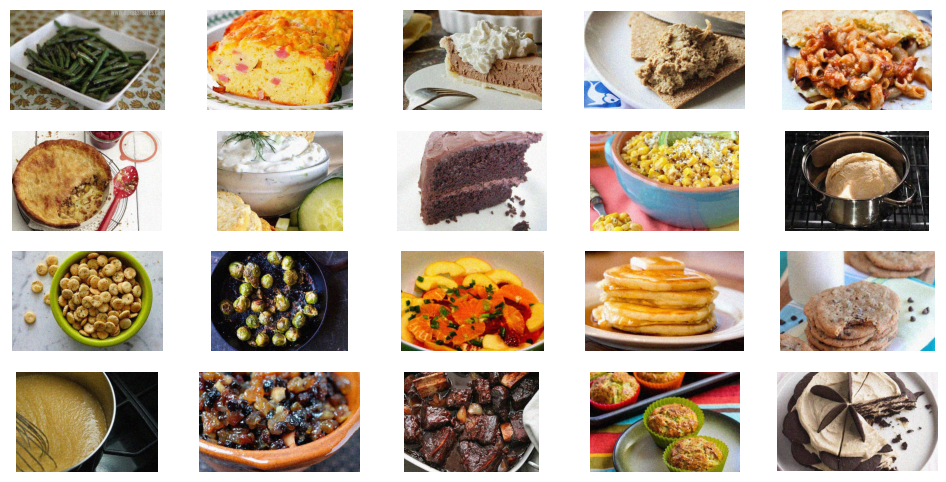

In [2]:
# Display images in dataset

import os
from PIL import Image
import matplotlib.pyplot as plt


dataset_path = "/home/albin/iml/iml-projects/task3/dataset/food/"

images = []
for i in range(20):
    image_path = os.path.join(dataset_path, "{0:0>{1}}.jpg".format(i, 5))
    
    with Image.open(image_path) as img:
            images.append(img.copy())

            
# Display multiple images in a row using subplots
num_cols = 5
num_rows = (len(images) + num_cols - 1) // num_cols
fig, axes = plt.subplots(num_rows, num_cols, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i < len(images):
        ax.imshow(images[i])
    ax.axis('off')
plt.show()

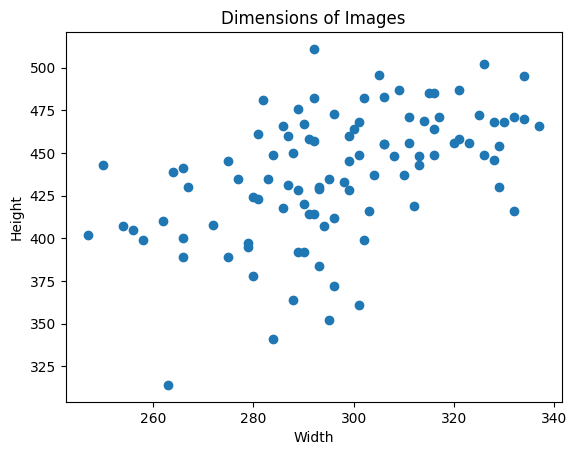

In [3]:
import matplotlib.pyplot as plt
import numpy as np

images = []
for i in range(100):
    image_path = os.path.join(dataset_path, "{0:0>{1}}.jpg".format(i, 5))
    
    with Image.open(image_path) as img:
            images.append(img.copy())

# Convert images to numpy arrays
images_np = [np.array(img) for img in images]

# create a list of tuples containing the dimensions of each image
image_dims = [(img.shape[0], img.shape[1]) for img in images_np]

# create a scatter plot of the dimensions
x, y = zip(*image_dims)
plt.scatter(x, y)
plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Dimensions of Images")
plt.show()

In [45]:
import numpy as np
from torchvision import transforms
from torch.utils.data import DataLoader, TensorDataset
import os
import torch
import torchvision.datasets as datasets
import torch.nn as nn
import torch.nn.functional as F

convert_tensor = transforms.Compose([
    #transforms.Resize((300, 300)),
    #transforms.CenterCrop(500),
    #transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    #transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
                                    ])
img_t = convert_tensor(images[1])
print('Original Image Dimensions:', img_t.shape)

Original Image Dimensions: torch.Size([3, 298, 433])


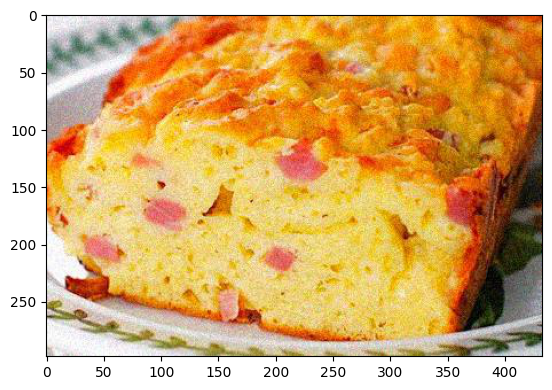

In [46]:
plt.imshow(img_t.permute(1, 2, 0))

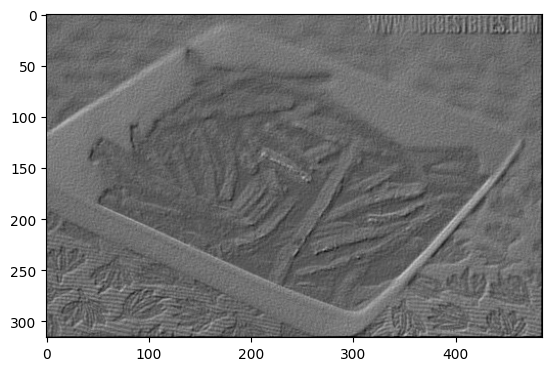

In [114]:
# blur kernel
conv_kernel = 0.11*torch.tensor([[[[1.,1.,1.],
                                   [1.,1.,1.],
                                   [1.,1.,1.]]]])

# emboss kernel
conv_kernel = 1.0*torch.tensor([[[[-2.,-1.,0.],
                                  [-1.,1.,1.],
                                  [0.,1.,2.]]]])

# convolve the image and the kernel
output = F.conv2d(img_t, conv_kernel, padding = 1)
# display convolved image
plt.imshow(output.permute(1, 2, 0), cmap="gray")
plt.show()

In [25]:
import numpy as np
from torchvision import transforms
from torch.utils.data import DataLoader, TensorDataset
import os
import torch
import torchvision.datasets as datasets
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Download and save MNIST dataset
data_train = datasets.MNIST('./mnist_data', train=True, download=True, transform=transforms.ToTensor())

# Print Data
print(data_train[0])

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000

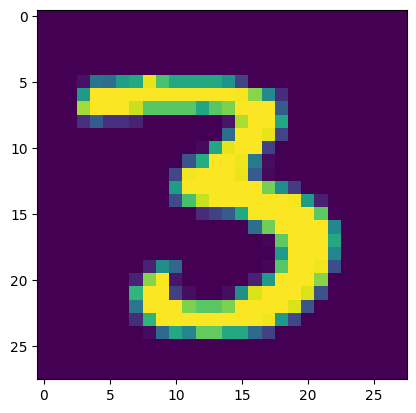

In [28]:
plt.imshow(data_train[12][0].permute(1, 2, 0))

In [30]:
data_loader = DataLoader(data_train, batch_size=64, shuffle=True) # 60000 images saved in 60000/64 chunks = 937 (mini-batches)


i = iter(data_loader)
a = next(i)

print(a[0])

tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        ...,


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0.

In [149]:
# If you want to load your own image dataset, use te ImageFolder class from torchvision.dataset. Save images in folders like:
#
# root
# ├── orange
# │   ├── orange_image1.png
# │   └── orange_image1.png
# ├── apple
# │   └── apple_image1.png
# │   └── apple_image2.png
# │   └── apple_image3.png
#
# Load images like this: 
# my_data = torchvision.datasets.ImageFolder(root, transform)

In [ ]:
# If you have GPU, use cuda:
device = "cuda" if torch.cuda.is_available() else "cpu"
kwargs = {'num_workers': 1, 'pin_memory': True} if device=='cuda' else {}

train_loader = DataLoader(
  torchvision.datasets.MNIST('/files/', train=True, download=True),
  batch_size=batch_size_train, **kwargs)

test_loader = DataLoader(
  torchvision.datasets.MNIST('files/', train=False, download=True),
  batch_size=batch_size, **kwargs)

## Layer dimensions

### Docs
```
torch.nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0, dilation=1, groups=1, bias=True, padding_mode='zeros', device=None, dtype=None)

torch.nn.functional.max_pool2d(input, kernel_size, stride=None, padding=0, dilation=1, ceil_mode=False, return_indices=False)

torch.nn.Linear(in_features, out_features, bias=True, device=None, dtype=None)
```

In [36]:
x = torch.rand(1,28,28) # ==> 1x28x28
print(x.shape)

conv1 = nn.Conv2d(1, 32, 3, 1) # [(W−K+2P)/S]+1 : (28-3)/1 + 1 = 26 ==> 32x26x26
conv2 = nn.Conv2d(32, 64, 3, 1) # [(W−K+2P)/S]+1 : (26-3)/1 + 1 = 24 ==> 64x24x24
# ...maxpool (default: stride = kernel_size)[(W−K+2P)/S]+1 : (24-2)/2 + 1 = 12 ==> 64x12x12
# ...flatten: 64*12*12 = 9216
fc1 = nn.Linear(9216, 128)
fc2 = nn.Linear(128, 10)
     
x = conv1(x)
print(f"After conv1: {x.shape}")
      
x = conv2(x)
print(f"After conv2: {x.shape}")
      
x = F.max_pool2d(x, 2)
print(f"After max_pool2d: {x.shape}")
      
x = torch.flatten(x)
print(f"After flatten: {x.shape}")
      
x = fc1(x)
print(f"After Linear1: {x.shape}")

x = fc2(x)
print(f"After Linear2: {x.shape}")

torch.Size([1, 28, 28])
After conv1: torch.Size([32, 26, 26])
After conv2: torch.Size([64, 24, 24])
After max_pool2d: torch.Size([64, 12, 12])
After flatten: torch.Size([9216])
After Linear1: torch.Size([128])
After Linear2: torch.Size([10])


In [73]:
train_dataset = datasets.ImageFolder(root="dataset/", transform=train_transforms)
len(train_dataset)

10000

In [75]:
with torch.no_grad():
    mysiu = iter(train_loader)
    data = next(mysiu)
    inputs, _ = data
    outputs = model(inputs)
    print(outputs.cpu().numpy().shape)

(64, 2048, 1, 1)


In [9]:
import os

triplets = []
with open('test_triplets.txt') as f:
        for line in f:
            triplets.append(line)

In [10]:
triplets

['09896 09640 09177\n',
 '06592 09283 07104\n',
 '08655 06174 06400\n',
 '09223 08187 08678\n',
 '07317 05392 09470\n',
 '09175 09545 08854\n',
 '06660 05883 06814\n',
 '06506 07220 05847\n',
 '08388 08012 06407\n',
 '09990 07083 09257\n',
 '05444 09740 08485\n',
 '05843 06341 07056\n',
 '06491 08050 07911\n',
 '06564 06085 06559\n',
 '06271 07130 05348\n',
 '06921 07958 07296\n',
 '06957 05029 07185\n',
 '08058 09793 07274\n',
 '08778 05913 05201\n',
 '08521 05702 09042\n',
 '09316 06804 06751\n',
 '05689 08406 05821\n',
 '09934 05025 06144\n',
 '07980 09608 09409\n',
 '09813 07842 07886\n',
 '05112 07007 06842\n',
 '06356 07529 07926\n',
 '08574 05013 07728\n',
 '08645 09388 06291\n',
 '08784 09479 06602\n',
 '07971 08884 07922\n',
 '07284 08137 06684\n',
 '07058 06644 06312\n',
 '07882 09960 08868\n',
 '06821 08535 06691\n',
 '08134 05099 06258\n',
 '07670 05589 06288\n',
 '08887 06998 05463\n',
 '09639 08795 07516\n',
 '07346 09524 06669\n',
 '08999 05081 09649\n',
 '08475 05389 07

In [28]:
triplets[0].split()

['09896', '09640', '09177']

In [4]:
import numpy as np

x = np.random.rand(4, 5, 1, 1)
y = np.reshape(x, (4,5))

In [5]:
li = []

li[0:4] = x

In [6]:
li[3]

array([[[0.69732711]],

       [[0.71924893]],

       [[0.32209551]],

       [[0.26428365]],

       [[0.66365755]]])

In [7]:
x

array([[[[0.42768127]],

        [[0.87591712]],

        [[0.21832721]],

        [[0.90788675]],

        [[0.12885706]]],


       [[[0.24423381]],

        [[0.6290793 ]],

        [[0.61914244]],

        [[0.3676034 ]],

        [[0.69964949]]],


       [[[0.48613666]],

        [[0.17447339]],

        [[0.85619687]],

        [[0.8102093 ]],

        [[0.50378467]]],


       [[[0.69732711]],

        [[0.71924893]],

        [[0.32209551]],

        [[0.26428365]],

        [[0.66365755]]]])

In [8]:
y

array([[0.42768127, 0.87591712, 0.21832721, 0.90788675, 0.12885706],
       [0.24423381, 0.6290793 , 0.61914244, 0.3676034 , 0.69964949],
       [0.48613666, 0.17447339, 0.85619687, 0.8102093 , 0.50378467],
       [0.69732711, 0.71924893, 0.32209551, 0.26428365, 0.66365755]])

In [19]:
import torchvision.datasets as datasets
# generate training data from triplets
train_dataset = datasets.ImageFolder(root="dataset/",
                                         transform=None)
s = train_dataset.samples[0]

In [20]:
k = s[0].split('/')[-1].replace('.jpg', '')
k

'00000'

In [25]:
s[0].split('/')[-1].replace('.jpg', '')

'00000'